# SmartBasket · Notebook 01 — Data loading and first A-Priori

**Team Frenchies** · Introduction to Big Data · Week 10

Goal of this notebook:
1. Load the Instacart dataset (3M orders, 32M basket lines) and **measure** what it costs in memory.
2. Describe the data: basket sizes, most popular products, the long tail.
3. Run a **first A-Priori** (frequent pairs + association rules) on a sample of orders.

Every number printed here is evidence for the weekly progress report.

> 🇫🇷 *Lancez les cellules une par une avec ▶ (ou Shift+Entrée). Chaque cellule a un commentaire en français qui explique ce qu'elle fait.*

## 0 · Setup

**Data — two ways, the notebook tries them in this order:**
1. **Google Drive (easiest for the team):** have a folder named `instacart` in *My Drive* (or a shortcut to the shared one) holding the Instacart CSV files. Colab asks you to allow Drive access: accept.
2. **Kaggle:** click the 🔑 key icon in the left bar (*Secrets*), add a secret named `KAGGLE_API_TOKEN` with your Kaggle token as value, and switch on *Notebook access*.

> 🇫🇷 *Si le dossier `instacart` est dans ton Drive, rien d'autre à faire. Sinon, le notebook passe par Kaggle. Aucune clé n'est écrite dans le notebook : le repo est public.*

In [1]:
# 🇫🇷 Imports + lecture du token Kaggle depuis les Secrets Colab (jamais en clair dans le code)
import os, time, json, gc
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
OUT = "out"
os.makedirs(OUT, exist_ok=True)

try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle token loaded from Colab secrets")
except Exception as e:
    print("Not on Colab or no secret set:", type(e).__name__)

Kaggle token loaded from Colab secrets


In [2]:
# 🇫🇷 Données : d'abord Google Drive (dossier « instacart »), sinon téléchargement Kaggle
DRIVE_DIR = "/content/drive/MyDrive/instacart"
DATA_DIR = os.environ.get("SB_DATA_DIR")          # local test only

if DATA_DIR is None:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        if os.path.exists(os.path.join(DRIVE_DIR, "order_products__prior.csv")):
            DATA_DIR = DRIVE_DIR
            print("Data found on Google Drive")
        else:
            print("No 'instacart' folder with the CSV files on Drive, trying Kaggle")
    except Exception as e:
        print("Google Drive not available:", type(e).__name__)

if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("psparks/instacart-market-basket-analysis")

for f in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, f)
    if os.path.isfile(p):
        print(f"{f:35s} {os.path.getsize(p)/1e6:8.1f} MB")

100%|██████████| 197M/197M [00:02<00:00, 74.7MB/s]

Extracting files...


aisles.csv                               0.0 MB
departments.csv                          0.0 MB
order_products__prior.csv              577.6 MB
order_products__train.csv               24.7 MB
orders.csv                             109.0 MB
products.csv                             2.2 MB


## 1 · Loading: what does it cost?

`order_products__prior.csv` is the big table: one line per (order, product).
We load it twice — once with pandas defaults, once with explicit small integer types — and compare the memory.

> 🇫🇷 *Par défaut pandas stocke chaque nombre sur 8 octets (int64). Nos identifiants tiennent sur 4 octets (int32) ou moins : on mesure la différence.*

In [3]:
# 🇫🇷 Chargement naïf (types par défaut) : on mesure temps et mémoire
PRIOR = os.path.join(DATA_DIR, "order_products__prior.csv")

t0 = time.time()
naive = pd.read_csv(PRIOR)
t_naive = time.time() - t0
mem_naive = naive.memory_usage(deep=True).sum() / 1e6
print(f"rows: {len(naive):,}")
print(naive.dtypes.to_string())
print(f"default load : {t_naive:5.1f} s   {mem_naive:8.1f} MB")
del naive; gc.collect()

rows: 32,434,489
order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
default load :  10.2 s     1037.9 MB


30

In [4]:
# 🇫🇷 Chargement optimisé : on impose des types plus petits
DTYPES = {"order_id": "int32", "product_id": "int32",
          "add_to_cart_order": "int16", "reordered": "int8"}

t0 = time.time()
prior = pd.read_csv(PRIOR, dtype=DTYPES)
t_opt = time.time() - t0
mem_opt = prior.memory_usage(deep=True).sum() / 1e6
print(f"typed load   : {t_opt:5.1f} s   {mem_opt:8.1f} MB")
print(f"memory saved : {100*(1-mem_opt/mem_naive):.1f} %")

products    = pd.read_csv(os.path.join(DATA_DIR, "products.csv"))
departments = pd.read_csv(os.path.join(DATA_DIR, "departments.csv"))
NAME = products.set_index("product_id")["product_name"].to_dict()

typed load   :  12.8 s      356.8 MB
memory saved : 65.6 %


## 2 · Describing the data

In [5]:
# 🇫🇷 Chiffres clés : combien de commandes, de produits, taille moyenne d'un panier
basket_size = prior.groupby("order_id").size()
stats = {
    "orders": int(prior["order_id"].nunique()),
    "basket_lines": int(len(prior)),
    "distinct_products_bought": int(prior["product_id"].nunique()),
    "catalogue_products": int(len(products)),
    "basket_size_mean": round(float(basket_size.mean()), 2),
    "basket_size_median": float(basket_size.median()),
    "basket_size_max": int(basket_size.max()),
}
for k, v in stats.items():
    print(f"{k:28s} {v:,}" if isinstance(v, int) else f"{k:28s} {v}")

orders                       3,214,874
basket_lines                 32,434,489
distinct_products_bought     49,677
catalogue_products           49,688
basket_size_mean             10.09
basket_size_median           8.0
basket_size_max              145


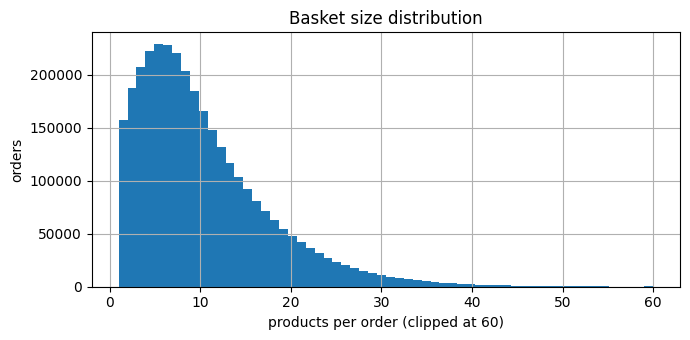

In [6]:
# 🇫🇷 Distribution de la taille des paniers
fig, ax = plt.subplots(figsize=(7, 3.5))
basket_size.clip(upper=60).hist(bins=60, ax=ax)
ax.set_xlabel("products per order (clipped at 60)"); ax.set_ylabel("orders")
ax.set_title("Basket size distribution")
plt.tight_layout(); plt.savefig(f"{OUT}/basket_size.png", dpi=120); plt.show()

In [7]:
# 🇫🇷 Les 10 produits les plus achetés : c'est aussi notre future baseline « popularité »
item_count = prior["product_id"].value_counts()
top10 = pd.DataFrame({
    "product": [NAME[i] for i in item_count.index[:10]],
    "orders": item_count.values[:10],
    "share_of_orders_%": (100 * item_count.values[:10] / stats["orders"]).round(2),
})
top10

,product,orders,share_of_orders_%
0,Banana,472565,14.70
1,Bag of Organic Bananas,379450,11.80
2,Organic Strawberries,264683,8.23
3,Organic Baby Spinach,241921,7.53
4,Organic Hass Avocado,213584,6.64
5,Organic Avocado,176815,5.50
6,Large Lemon,152657,4.75
7,Strawberries,142951,4.45
8,Limes,140627,4.37
9,Organic Whole Milk,137905,4.29


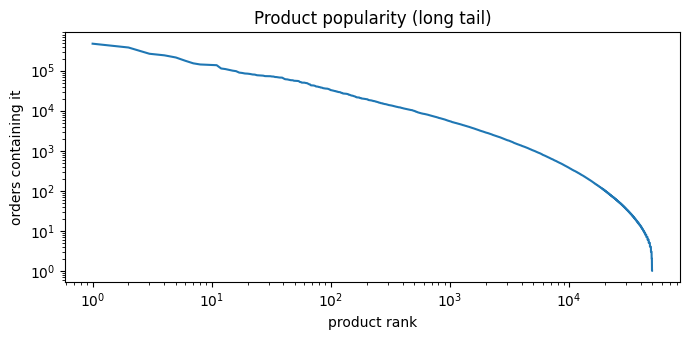

products in at least     1% of orders: 102
products in at least   0.1% of orders: 1,772
products in at least  0.01% of orders: 10,906


In [8]:
# 🇫🇷 La « longue traîne » : quelques produits très populaires, des milliers très rares (échelle log-log)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.loglog(np.arange(1, len(item_count) + 1), item_count.values)
ax.set_xlabel("product rank"); ax.set_ylabel("orders containing it")
ax.set_title("Product popularity (long tail)")
plt.tight_layout(); plt.savefig(f"{OUT}/long_tail.png", dpi=120); plt.show()

for pct in (1, 0.1, 0.01):
    n = int((item_count >= stats["orders"] * pct / 100).sum())
    print(f"products in at least {pct:>5}% of orders: {n:,}")

## 3 · First A-Priori on a sample

We take a random sample of orders (fixed seed so results are reproducible), turn each order into a **basket** (a set of product ids), and run the two-pass A-Priori from lab 6:

- **pass 1** — count single items, keep those with count ≥ support;
- **pass 2** — count only pairs whose two items both survived pass 1.

Then for each frequent pair {A, B} we compute the rules A→B and B→A:

| measure | formula | meaning |
|---|---|---|
| support | count(A,B) | how many baskets contain both |
| confidence | count(A,B) / count(A) | among baskets with A, share that also has B |
| lift | confidence / (count(B)/N) | > 1 means A really raises the chance of B |

> 🇫🇷 *Même logique que `task1_apriori.py` du lab 6, appliquée à de vraies commandes.*

In [9]:
# 🇫🇷 Paramètres : taille de l'échantillon et seuil de support (en % des paniers)
SAMPLE_ORDERS = 50_000
SUPPORT_PCT   = 0.5          # a pair must appear in at least 0.5 % of the baskets

rng = np.random.default_rng(SEED)
all_orders = prior["order_id"].unique()
sample_ids = rng.choice(all_orders, size=min(SAMPLE_ORDERS, len(all_orders)), replace=False)
sample = prior[prior["order_id"].isin(sample_ids)]

baskets = sample.groupby("order_id")["product_id"].apply(frozenset).tolist()
N = len(baskets)
SUPPORT = max(1, int(N * SUPPORT_PCT / 100))
print(f"baskets: {N:,}   support threshold: {SUPPORT} baskets ({SUPPORT_PCT}%)")

baskets: 50,000   support threshold: 250 baskets (0.5%)


In [10]:
# 🇫🇷 A-Priori en deux passes, avec mesure du temps et du nombre de compteurs
def apriori_pairs(baskets, support):
    # pass 1: count every single item
    item_counts = Counter()
    for b in baskets:
        item_counts.update(b)
    frequent_items = {i: c for i, c in item_counts.items() if c >= support}

    # pass 2: count only pairs made of two frequent items (the A-Priori trick)
    pair_counts = Counter()
    for b in baskets:
        kept = sorted(i for i in b if i in frequent_items)
        pair_counts.update(combinations(kept, 2))
    frequent_pairs = {p: c for p, c in pair_counts.items() if c >= support}

    info = {"distinct_items": len(item_counts),
            "frequent_items": len(frequent_items),
            "pair_counters": len(pair_counts),
            "frequent_pairs": len(frequent_pairs)}
    return frequent_items, frequent_pairs, info

t0 = time.time()
freq_items, freq_pairs, info = apriori_pairs(baskets, SUPPORT)
info["seconds"] = round(time.time() - t0, 2)

n_items = info["distinct_items"]
info["brute_force_pair_counters"] = n_items * (n_items - 1) // 2
for k, v in info.items():
    print(f"{k:28s} {v:,}")

distinct_items               29,207
frequent_items               257
pair_counters                31,308
frequent_pairs               82
seconds                      0.48
brute_force_pair_counters    426,509,821


In [11]:
# 🇫🇷 Règles d'association A→B et B→A pour chaque paire fréquente
def rules_from_pairs(freq_pairs, freq_items, n):
    rows = []
    for (a, b), c_ab in freq_pairs.items():
        for x, y in ((a, b), (b, a)):
            conf = c_ab / freq_items[x]
            lift = conf / (freq_items[y] / n)
            rows.append({"if_bought": NAME.get(x, x), "then_buy": NAME.get(y, y),
                         "support": c_ab, "confidence": round(conf, 3),
                         "lift": round(lift, 2), "a_id": x, "b_id": y})
    return pd.DataFrame(rows)

rules = rules_from_pairs(freq_pairs, freq_items, N)
print(f"rules: {len(rules):,}")
rules.to_csv(f"{OUT}/rules_week10.csv", index=False)

rules: 164


### Same rules, two rankings

Sort by **confidence** first, then by **lift**, and compare the two top-10 lists.

> 🇫🇷 *Regardez si les mêmes produits très populaires reviennent partout dans le classement par confiance : c'est le point à discuter dans le rapport.*

In [12]:
# 🇫🇷 Top 10 par confiance
cols = ["if_bought", "then_buy", "support", "confidence", "lift"]
rules.sort_values("confidence", ascending=False)[cols].head(10).reset_index(drop=True)

,if_bought,then_buy,support,confidence,lift
0,Organic Fuji Apple,Banana,512,0.392,2.67
1,Honeycrisp Apple,Banana,446,0.366,2.50
2,Organic D'Anjou Pears,Bag of Organic Bananas,251,0.332,2.76
3,Cucumber Kirby,Banana,508,0.329,2.25
4,Organic Avocado,Banana,836,0.305,2.08
5,Organic Raspberries,Bag of Organic Bananas,667,0.299,2.49
6,Organic Large Extra Fancy Fuji Apple,Bag of Organic Bananas,349,0.299,2.49
7,Seedless Red Grapes,Banana,366,0.298,2.03
8,Organic Cucumber,Bag of Organic Bananas,366,0.289,2.40
9,Strawberries,Banana,618,0.288,1.97


In [13]:
# 🇫🇷 Top 10 par lift
rules.sort_values("lift", ascending=False)[cols].head(10).reset_index(drop=True)

,if_bought,then_buy,support,confidence,lift
0,Limes,Organic Cilantro,268,0.123,6.10
1,Organic Cilantro,Limes,268,0.266,6.10
2,Organic Garlic,Organic Yellow Onion,356,0.211,5.86
3,Organic Yellow Onion,Organic Garlic,356,0.197,5.86
4,Limes,Large Lemon,431,0.197,4.16
5,Large Lemon,Limes,431,0.182,4.16
6,Organic Lemon,Organic Hass Avocado,369,0.256,3.85
7,Organic Hass Avocado,Organic Lemon,369,0.111,3.85
8,Organic Hass Avocado,Organic Cucumber,279,0.084,3.31
9,Organic Cucumber,Organic Hass Avocado,279,0.220,3.31


In [14]:
# 🇫🇷 Combien de fois les produits du top 10 popularité apparaissent dans « then_buy » des deux classements
popular = set(item_count.index[:10])
def popular_share(df):
    return int(df["b_id"].isin(popular).sum())
by_conf = rules.sort_values("confidence", ascending=False).head(10)
by_lift = rules.sort_values("lift", ascending=False).head(10)
print("top-10 by confidence → consequent is a top-10 popular product:", popular_share(by_conf), "/ 10")
print("top-10 by lift       → consequent is a top-10 popular product:", popular_share(by_lift), "/ 10")

top-10 by confidence → consequent is a top-10 popular product: 10 / 10
top-10 by lift       → consequent is a top-10 popular product: 5 / 10


## 4 · Evidence for the progress report

In [15]:
# 🇫🇷 Tous les chiffres de la semaine dans un seul fichier : à copier dans le rapport
evidence = {
    "load": {"default_MB": round(mem_naive, 1), "typed_MB": round(mem_opt, 1),
             "default_s": round(t_naive, 1), "typed_s": round(t_opt, 1)},
    "dataset": stats,
    "apriori_sample": {"baskets": N, "support_pct": SUPPORT_PCT,
                       "support_baskets": SUPPORT, **info, "rules": len(rules)},
    "top_by_confidence_popular_consequents": popular_share(by_conf),
    "top_by_lift_popular_consequents": popular_share(by_lift),
}
with open(f"{OUT}/evidence_week10.json", "w") as f:
    json.dump(evidence, f, indent=2)
print(json.dumps(evidence, indent=2))

{
  "load": {
    "default_MB": 1037.9,
    "typed_MB": 356.8,
    "default_s": 10.2,
    "typed_s": 12.8
  },
  "dataset": {
    "orders": 3214874,
    "basket_lines": 32434489,
    "distinct_products_bought": 49677,
    "catalogue_products": 49688,
    "basket_size_mean": 10.09,
    "basket_size_median": 8.0,
    "basket_size_max": 145
  },
  "apriori_sample": {
    "baskets": 50000,
    "support_pct": 0.5,
    "support_baskets": 250,
    "distinct_items": 29207,
    "frequent_items": 257,
    "pair_counters": 31308,
    "frequent_pairs": 82,
    "seconds": 0.48,
    "brute_force_pair_counters": 426509821,
    "rules": 164
  },
  "top_by_confidence_popular_consequents": 10,
  "top_by_lift_popular_consequents": 5
}


> 🇫🇷 **À faire après l'exécution :** copiez la sortie de la cellule ci-dessus et envoyez-la (avec les deux tableaux top 10). Téléchargez aussi le dossier `out/` (icône dossier à gauche) pour le mettre dans le repo.